## Đề tài: Phân tích và dự đoán sức khỏe tâm thần thanh thiếu niên - Philippines

Sức khỏe tâm thần ở thanh thiếu niên là một vấn đề quan trọng, có ảnh hưởng đến chất lượng cuộc sống, kết quả học tập và sự phát triển lâu dài của mỗi cá nhân. Việc phân tích dữ liệu khảo sát giúp tìm hiểu tình trạng sức khỏe tâm thần, nhận diện các yếu tố có liên quan và xây dựng mô hình dự đoán phục vụ mục đích nghiên cứu.

Mục tiêu: Khám phá dữ liệu, kiểm tra chất lượng, phân tích câu trả lời Q24 và thử 5 mô hình phân loại. Mô hình chỉ dự đoán câu trả lời khảo sát, không chẩn đoán bệnh tâm thần.

In [3]:
#Khai báo thư viện
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option("display.max_columns", 150)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
print("Đã import các thư viện thành công.")

Đã import các thư viện thành công.


## PHẦN 1: TỔNG QUAN VỀ TẬP DỮ LIỆU GSHS PHILIPPINES 2019 VÀ KIỂM TRA DỮ LIỆU KHUYẾT THIẾU

Trong đề tài này, tập dữ liệu PHL2019 (Visayas).csv được sử dụng để phân tích dữ liệu sức khỏe và hành vi của thanh thiếu niên PhilippineS năm 2019. Dữ liệu thuộc chương trình Global School-based Student Health Survey (GSHS), một chương trình khảo sát sức khỏe học sinh trong môi trường trường học.


Tập dữ liệu gồm 3.149 bản ghi và 104 cột. Các biến bao gồm thông tin nhân khẩu học, câu trả lời khảo sát về sức khỏe và hành vi, cùng một số trường phục vụ quản lý bản ghi và thiết kế mẫu khảo sát.

Các biến trong tập dữ liệu có thể được chia thành những nhóm chính sau:

Nhóm thông tin nhân khẩu học: tuổi (q1), giới tính (q2), lớp học (q3), nếu được xác nhận theo codebook của bộ dữ liệu.

Nhóm sức khỏe tâm thần: cảm giác cô đơn (q22), lo lắng đến mức không ngủ được (q23) và cân nhắc tự tử (q24), sau khi xác minh nội dung và cách mã hóa của từng câu hỏi.

Nhóm thông tin khảo sát và thiết kế mẫu: địa điểm khảo sát (site), mã bản ghi (record), trọng số khảo sát (weight), tầng mẫu (stratum) và đơn vị lấy mẫu sơ cấp (psu).

In [4]:
#Đọc file CSV
DATA_DIR = Path(r"D:\BaoCaoPython\Mental_Health_ML\data")
CSV_PATH = DATA_DIR / "PHL2019 (Visayas).csv"

if not CSV_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy {CSV_PATH}. Hãy sửa DATA_DIR/CSV_PATH.")

df = pd.read_csv(CSV_PATH)
df.columns = df.columns.astype(str).str.strip().str.lower()
print("Quốc gia: Philippines")
print("Kích thước dữ liệu: ", df.shape)
display(df.head())

Quốc gia: Philippines
Kích thước dữ liệu:  (3149, 104)


,site,record,weight,stratum,psu,q1,q2,q3,q4,q5,q6,q10,q11,q12,q13,q14,q15,q16,q17,q18,q19,q22,q23,q24,q25,q26,q27,q34,q35,q36,q37,q38,q39,q40,q41,q42,q49,q50,q51,q52,q53,q54,q55,q56,q57,q58,q62,q63,q64,q76,q77,q79,qn6,qn10,qn11,qn12,qn13,qn14,qn15,qn16,qn17,qn18,qn19,qn22,qn23,qn24,qn25,qn26,qn27,qn34,qn35,qn36,qn37,qn38,qn39,qn40,qn41,qn42,qn49,qn50,qn51,qn52,qn53,qn54,qn55,qn56,qn57,qn58,qn62,qn63,qn64,qn76,qn77,qn79,qnunwtg,qnowtg,qnobeseg,qnff1g,qnff2g,qnff3g,qnpa5g,qnpa7g,qnpe3g,qnpe5g
0,PIB,1,609.8739,201902006,12,4.0,1.0,2.0,NaN,NaN,3.0,1.0,5.0,3.0,5.0,4.0,2,2.0,5.0,8.0,8.0,2.0,2.0,2.0,2.0,1.0,2.0,5.0,2.0,3.0,5.0,2.0,1.0,1.0,1.0,1.0,1.0,6.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,3,2.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,2.0,NaN,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2,2.0,1.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,1.0,2.0
1,PIB,2,520.2954,201902006,12,4.0,2.0,2.0,NaN,NaN,3.0,1.0,4.0,5.0,5.0,3.0,1,1.0,1.0,1.0,1.0,2.0,3.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0,1.0,3.0,5.0,5.0,5.0,1.0,2.0,3.0,4,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2,2.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2,2.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,1.0,2.0
2,PIB,3,520.2954,201902006,12,4.0,2.0,2.0,NaN,NaN,3.0,1.0,5.0,3.0,4.0,3.0,1,1.0,1.0,1.0,1.0,3.0,3.0,1.0,1.0,3.0,4.0,6.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,3.0,5.0,3.0,2.0,2.0,3.0,2.0,2.0,2.0,2.0,2.0,2.0,3,1.0,2.0,NaN,2.0,1.0,1.0,2.0,2.0,2.0,2,2.0,2.0,NaN,NaN,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,NaN,NaN,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2,1.0,2.0,NaN,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0
3,PIB,4,520.2954,201902006,12,2.0,2.0,2.0,NaN,NaN,1.0,3.0,5.0,5.0,5.0,5.0,4,1.0,1.0,1.0,1.0,5.0,5.0,2.0,2.0,1.0,2.0,5.0,2.0,6.0,4.0,3.0,2.0,1.0,1.0,1.0,NaN,1.0,2.0,3.0,2.0,3.0,3.0,1.0,5.0,3.0,2.0,2.0,2,2.0,1.0,NaN,2.0,2.0,1.0,2.0,2.0,2.0,1,2.0,2.0,NaN,NaN,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,2.0,2.0,NaN,1.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2,2.0,1.0,NaN,NaN,NaN,NaN,1.0,1.0,2.0,NaN,NaN,2.0,2.0
4,PIB,5,520.2954,201902006,12,3.0,2.0,2.0,NaN,NaN,1.0,1.0,5.0,5.0,5.0,5.0,1,1.0,2.0,1.0,1.0,3.0,1.0,NaN,2.0,2.0,4.0,5.0,2.0,2.0,3.0,3.0,4.0,1.0,1.0,1.0,4.0,6.0,4.0,1.0,3.0,3.0,1.0,1.0,3.0,1.0,4.0,1.0,3,1.0,1.0,NaN,2.0,1.0,1.0,2.0,2.0,2.0,2,2.0,1.0,NaN,NaN,2.0,2.0,NaN,2.0,1.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2,1.0,1.0,NaN,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,1.0,2.0


## 2. Kiểm tra cấu trúc dữ liệu

Mục tiêu:
- Xác định số lượng mẫu và số lượng biến.
- Quan sát các dòng dữ liệu đầu tiên.
- Kiểm tra kiểu dữ liệu của các biến.

In [5]:
# 1. Kích thước dữ liệu
print("Số dòng: ", df.shape[0])
print("Số cột: ", df.shape[1])

display(df.head(10))
display(df.tail())

Số dòng:  3149
Số cột:  104


,site,record,weight,stratum,psu,q1,q2,q3,q4,q5,q6,q10,q11,q12,q13,q14,q15,q16,q17,q18,q19,q22,q23,q24,q25,q26,q27,q34,q35,q36,q37,q38,q39,q40,q41,q42,q49,q50,q51,q52,q53,q54,q55,q56,q57,q58,q62,q63,q64,q76,q77,q79,qn6,qn10,qn11,qn12,qn13,qn14,qn15,qn16,qn17,qn18,qn19,qn22,qn23,qn24,qn25,qn26,qn27,qn34,qn35,qn36,qn37,qn38,qn39,qn40,qn41,qn42,qn49,qn50,qn51,qn52,qn53,qn54,qn55,qn56,qn57,qn58,qn62,qn63,qn64,qn76,qn77,qn79,qnunwtg,qnowtg,qnobeseg,qnff1g,qnff2g,qnff3g,qnpa5g,qnpa7g,qnpe3g,qnpe5g
0,PIB,1,609.8739,201902006,12,4.0,1.0,2.0,NaN,NaN,3.0,1.0,5.0,3.0,5.0,4.0,2,2.0,5.0,8.0,8.0,2.0,2.0,2.0,2.0,1.0,2.0,5.0,2.0,3.0,5.0,2.0,1.0,1.0,1.0,1.0,1.0,6.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,1.0,3,2.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,2.0,NaN,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2,2.0,1.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,1.0,2.0
1,PIB,2,520.2954,201902006,12,4.0,2.0,2.0,NaN,NaN,3.0,1.0,4.0,5.0,5.0,3.0,1,1.0,1.0,1.0,1.0,2.0,3.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.0,1.0,1.0,3.0,5.0,5.0,5.0,1.0,2.0,3.0,4,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2,2.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,2,2.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,1.0,2.0
2,PIB,3,520.2954,201902006,12,4.0,2.0,2.0,NaN,NaN,3.0,1.0,5.0,3.0,4.0,3.0,1,1.0,1.0,1.0,1.0,3.0,3.0,1.0,1.0,3.0,4.0,6.0,1.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,3.0,5.0,3.0,2.0,2.0,3.0,2.0,2.0,2.0,2.0,2.0,2.0,3,1.0,2.0,NaN,2.0,1.0,1.0,2.0,2.0,2.0,2,2.0,2.0,NaN,NaN,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,NaN,NaN,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2,1.0,2.0,NaN,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0
3,PIB,4,520.2954,201902006,12,2.0,2.0,2.0,NaN,NaN,1.0,3.0,5.0,5.0,5.0,5.0,4,1.0,1.0,1.0,1.0,5.0,5.0,2.0,2.0,1.0,2.0,5.0,2.0,6.0,4.0,3.0,2.0,1.0,1.0,1.0,NaN,1.0,2.0,3.0,2.0,3.0,3.0,1.0,5.0,3.0,2.0,2.0,2,2.0,1.0,NaN,2.0,2.0,1.0,2.0,2.0,2.0,1,2.0,2.0,NaN,NaN,1.0,1.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,2.0,2.0,NaN,1.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2,2.0,1.0,NaN,NaN,NaN,NaN,1.0,1.0,2.0,NaN,NaN,2.0,2.0
4,PIB,5,520.2954,201902006,12,3.0,2.0,2.0,NaN,NaN,1.0,1.0,5.0,5.0,5.0,5.0,1,1.0,2.0,1.0,1.0,3.0,1.0,NaN,2.0,2.0,4.0,5.0,2.0,2.0,3.0,3.0,4.0,1.0,1.0,1.0,4.0,6.0,4.0,1.0,3.0,3.0,1.0,1.0,3.0,1.0,4.0,1.0,3,1.0,1.0,NaN,2.0,1.0,1.0,2.0,2.0,2.0,2,2.0,1.0,NaN,NaN,2.0,2.0,NaN,2.0,1.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,2,1.0,1.0,NaN,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,1.0,2.0
5,PIB,6,609.8739,201902006,12,5.0,1.0,2.0,NaN,NaN,2.0,1.0,5.0,5.0,5.0,2.0,2,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,3.0,2.0,2.0,3.0,2.0,2.0,3.0,1,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,1,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1,1.0,1.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0
6,PIB,7,609.8739,201902006,12,3.0,1.0,NaN,NaN,NaN,1.0,1.0,5.0,5.0,5.0,5.0,1,1.0,2.0,1.0,1.0,3.0,2.0,2.0,2.0,1.0,2.0,4.0,1.0,3.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,8.0,1.0,2.0,3.0,4.0,2.0,2.0,2.0,2.0,6.0,6.0,4,1.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,NaN,2.0,2.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2,1.0,1.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0
7,PIB,8,520.2954,201902006,12,4.0,2.0,2.0,NaN,NaN,2.0,1.0,5.0,5.0,5.0,5.0,2,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,3.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,2.0,3.0,2.0,5.0,5.0,3.0,2.0,2.0,2,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1,2.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,1.0,1.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2,2.0,2.0,2.0,NaN,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0
8,PIB,9,609.8739,201902006,12,4.0,1.0,2.0,NaN,NaN,1.0,2.0,5.0,5.0,5.0,5.0,1,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,4.0,6.0,2.0,3.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,

,site,record,weight,stratum,psu,q1,q2,q3,q4,q5,q6,q10,q11,q12,q13,q14,q15,q16,q17,q18,q19,q22,q23,q24,q25,q26,q27,q34,q35,q36,q37,q38,q39,q40,q41,q42,q49,q50,q51,q52,q53,q54,q55,q56,q57,q58,q62,q63,q64,q76,q77,q79,qn6,qn10,qn11,qn12,qn13,qn14,qn15,qn16,qn17,qn18,qn19,qn22,qn23,qn24,qn25,qn26,qn27,qn34,qn35,qn36,qn37,qn38,qn39,qn40,qn41,qn42,qn49,qn50,qn51,qn52,qn53,qn54,qn55,qn56,qn57,qn58,qn62,qn63,qn64,qn76,qn77,qn79,qnunwtg,qnowtg,qnobeseg,qnff1g,qnff2g,qnff3g,qnpa5g,qnpa7g,qnpe3g,qnpe5g
3144,PIB,3147,440.4526,201902011,22,5.0,2.0,4.0,1.49,45.0,3.0,1.0,4.0,5.0,5.0,5.0,1,1.0,1.0,1.0,1.0,3.0,4.0,2.0,2.0,1.0,4.0,6.0,2.0,3.0,2.0,1.0,1.0,1.0,1.0,1.0,8.0,1.0,6.0,2.0,1.0,4.0,2.0,2.0,2.0,2.0,3.0,2.0,2,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2,2.0,2.0,NaN,NaN,2.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,NaN,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,2.0,2,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0
3145,PIB,3148,440.4526,201902011,22,6.0,2.0,4.0,1.47,49.0,1.0,1.0,3.0,5.0,5.0,5.0,2,1.0,NaN,NaN,NaN,3.0,4.0,2.0,2.0,2.0,4.0,6.0,2.0,7.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,8.0,6.0,4.0,2.0,3.0,2.0,5.0,4.0,1.0,3.0,3.0,2,1.0,NaN,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1,2.0,NaN,NaN,NaN,2.0,1.0,2.0,2.0,1.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2,1.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0
3146,PIB,3149,440.4526,201902011,22,5.0,2.0,4.0,1.45,50.0,1.0,1.0,4.0,3.0,4.0,3.0,1,3.0,1.0,1.0,1.0,2.0,3.0,2.0,2.0,1.0,4.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,3.0,8.0,2.0,3.0,1.0,3.0,3.0,2.0,2.0,1.0,4.0,5.0,1,2.0,1.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2,1.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,NaN,2.0,NaN,NaN,2.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,1,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
3147,PIB,3150,440.4526,201902011,22,6.0,2.0,4.0,1.39,36.0,2.0,1.0,4.0,5.0,5.0,5.0,3,1.0,2.0,1.0,1.0,2.0,3.0,2.0,2.0,1.0,4.0,6.0,2.0,7.0,4.0,4.0,1.0,1.0,1.0,1.0,1.0,8.0,2.0,6.0,1.0,5.0,1.0,1.0,1.0,1.0,2.0,1.0,2,2.0,2.0,NaN,2.0,1.0,1.0,2.0,2.0,2.0,1,2.0,1.0,NaN,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,NaN,2.0,2.0,1.0,2.0,2.0,1.0,2.0,1.0,2.0,2.0,2.0,1.0,2.0,1.0,2,2.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0
3148,PIB,3151,514.9935,201902011,22,6.0,1.0,4.0,1.63,43.0,2.0,1.0,4.0,5.0,5.0,4.0,1,3.0,1.0,1.0,1.0,3.0,1.0,2.0,2.0,NaN,1.0,6.0,2.0,7.0,4.0,2.0,1.0,1.0,1.0,1.0,1.0,3.0,1.0,4.0,1.0,3.0,1.0,1.0,2.0,1.0,3.0,5.0,5,1.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,2,1.0,2.0,NaN,NaN,2.0,2.0,2.0,2.0,NaN,1.0,2.0,1.0,1.0,1.0,1.0,2.0,NaN,2.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,2,1.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0


In [6]:
# Danh sách tên tất cả các cột
print("Danh sách tên cột:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")
print("\n Thông tin tổng quan:")
df.info()

Danh sách tên cột:
1. site
2. record
3. weight
4. stratum
5. psu
6. q1
7. q2
8. q3
9. q4
10. q5
11. q6
12. q10
13. q11
14. q12
15. q13
16. q14
17. q15
18. q16
19. q17
20. q18
21. q19
22. q22
23. q23
24. q24
25. q25
26. q26
27. q27
28. q34
29. q35
30. q36
31. q37
32. q38
33. q39
34. q40
35. q41
36. q42
37. q49
38. q50
39. q51
40. q52
41. q53
42. q54
43. q55
44. q56
45. q57
46. q58
47. q62
48. q63
49. q64
50. q76
51. q77
52. q79
53. qn6
54. qn10
55. qn11
56. qn12
57. qn13
58. qn14
59. qn15
60. qn16
61. qn17
62. qn18
63. qn19
64. qn22
65. qn23
66. qn24
67. qn25
68. qn26
69. qn27
70. qn34
71. qn35
72. qn36
73. qn37
74. qn38
75. qn39
76. qn40
77. qn41
78. qn42
79. qn49
80. qn50
81. qn51
82. qn52
83. qn53
84. qn54
85. qn55
86. qn56
87. qn57
88. qn58
89. qn62
90. qn63
91. qn64
92. qn76
93. qn77
94. qn79
95. qnunwtg
96. qnowtg
97. qnobeseg
98. qnff1g
99. qnff2g
100. qnff3g
101. qnpa5g
102. qnpa7g
103. qnpe3g
104. qnpe5g

 Thông tin tổng quan:
<class 'pandas.DataFrame'>
RangeIndex: 3149 entries

In [7]:
#Kiểm tra trùng lặp và dữ liệu thiếu
duplicate_count = df.duplicated().sum()
print("Số dòng trùng hoàn toàn:", duplicate_count)

missing_count = df.isna().sum()
missing_table = pd.DataFrame({
    "Số giá trị thiếu": missing_count,
    "Tỷ lệ thiếu (%)": (
        missing_count / len(df) * 100
    ).round(2)
})

missing_table = missing_table[missing_table["Số giá trị thiếu"] > 0
                              ].sort_values(by="Tỷ lệ thiếu (%)", ascending=False)
print("\n Các cột có dữ liệu thiếu:")
display(missing_table)

Số dòng trùng hoàn toàn: 0

 Các cột có dữ liệu thiếu:


,Số giá trị thiếu,Tỷ lệ thiếu (%)
qn40,2680,85.11
qn18,2421,76.88
qn19,2400,76.21
qn37,2340,74.31
qn36,2220,70.50
qn34,1760,55.89
q4,757,24.04
qnowtg,757,24.04
qnunwtg,757,24.04
q5,757,24.04


### 💡 Nhận xét ban đầu về dữ liệu khuyết thiếu:

1. **Các biến có tỷ lệ khuyết thiếu cao:** Một số câu hỏi khảo sát có thể có tỷ lệ dữ liệu khuyết thiếu đáng kể. Những biến này cần được kiểm tra để xác định nguyên nhân và mức độ ảnh hưởng đến kết quả phân tích. Không nên loại bỏ toàn bộ biến chỉ vì tỷ lệ thiếu cao, đặc biệt nếu biến đó có ý nghĩa đối với nghiên cứu sức khỏe tâm thần.

2. **Các biến sức khỏe tâm thần (`q22`, `q23`, `q24`):** Đây là những biến quan trọng để phân tích cảm giác cô đơn, tình trạng lo lắng gây mất ngủ và việc cân nhắc tự tử. Cần thống kê riêng số lượng và tỷ lệ khuyết thiếu của từng biến. Nếu `q24` được chọn làm biến mục tiêu dự đoán, các bản ghi thiếu câu trả lời hợp lệ ở biến này cần được xem xét riêng, thay vì tự động gán thành câu trả lời “Không”.

3. **Các biến nhân khẩu học (`q1`, `q2`, `q3`):** Các biến tuổi, giới tính và lớp học có thể được sử dụng để tìm hiểu sự khác biệt giữa các nhóm học sinh. Nếu tỷ lệ khuyết thiếu thấp, có thể cân nhắc bổ sung bằng giá trị phù hợp, chẳng hạn giá trị xuất hiện nhiều nhất đối với biến phân loại. Nếu tỷ lệ thiếu cao, cần đánh giá kỹ trước khi quyết định cách xử lý.

4. **Các cột phục vụ thiết kế mẫu (`site`, `record`, `weight`, `stratum`, `psu`):** Đây là các trường thông tin phục vụ nhận diện bản ghi hoặc thiết kế khảo sát. Cần kiểm tra dữ liệu thiếu và vai trò của chúng trước khi phân tích. Đặc biệt, `weight`, `stratum` và `psu` có thể quan trọng khi thực hiện thống kê có xét đến thiết kế mẫu khảo sát.

5. **Hướng xử lý dữ liệu khuyết thiếu:** Không thay thế tất cả giá trị thiếu bằng 0 vì điều này có thể làm sai lệch ý nghĩa của câu trả lời. Việc xử lý sẽ dựa trên tỷ lệ thiếu, loại biến, ý nghĩa của các mã câu trả lời và yêu cầu của mô hình. Những mã đặc biệt như 7, 8, 9 hoặc 99 chỉ được xem là dữ liệu thiếu khi có xác nhận từ codebook.

In [8]:
# Các câu hỏi cần kiểm tra
questions = [1, 2, 3, 15, 16, 17, 18, 19, 22, 23, 24, 25, 26, 27]

def find_question_columns(df, question_numbers):
    results = {}
    for number in question_numbers:
        matches = []
        for col in df.columns:
            # Chuẩn hóa tên cột
            normalized = re.sub(
                r"[^a-z0-9]",
                "",
                str(col).lower()
            )
            # Chỉ khớp đúng số câu hỏi, tránh nhầm q1 với q10
            pattern = rf"^(?:qn?|question)0*{number}(?:\D|$)"
            if re.search(pattern, normalized):
                matches.append(col)
        results[f"Q{number}"] = matches
    return results

question_columns = find_question_columns(df, questions)
for question, columns in question_columns.items():
    print(f"{question}: {columns if columns else 'Chưa tìm thấy'}")


Q1: ['q1']
Q2: ['q2']
Q3: ['q3']
Q15: ['q15', 'qn15']
Q16: ['q16', 'qn16']
Q17: ['q17', 'qn17']
Q18: ['q18', 'qn18']
Q19: ['q19', 'qn19']
Q22: ['q22', 'qn22']
Q23: ['q23', 'qn23']
Q24: ['q24', 'qn24']
Q25: ['q25', 'qn25']
Q26: ['q26', 'qn26']
Q27: ['q27', 'qn27']


In [9]:
Q24_COL = "q24"
if Q24_COL not in df.columns:
    raise KeyError(
        f"Không tìm thấy cột {Q24_COL}."
    )
print("Phân phối giá trị q24:")
display(
    df[Q24_COL]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("Mã trả lời")
    .to_frame("Số lượng")
)

Phân phối giá trị q24:


,Số lượng
Mã trả lời,
1.0,593
2.0,2417
NaN,139


In [10]:
FEATURE_COLS = [
    "q1",
    "q2",
    "q15",
    "q16",
    "q17",
    "q22",
    "q23",
    "q27"
]

missing_columns = [
    col for col in FEATURE_COLS
    if col not in df.columns
]

if missing_columns:
    print("Các cột chưa tìm thấy:", missing_columns)
else:
    print("Đã tìm thấy tất cả các cột đầu tiên vào.")
    for col in FEATURE_COLS:
        print(f"\n Phân phối {col}:")
        display(
            df[col]
            .value_counts(dropna=False)
            .sort_index()
            .rename_axis("Mã trả lời")
            .to_frame("Số lượng")
        )

Đã tìm thấy tất cả các cột đầu tiên vào.

 Phân phối q1:


,Số lượng
Mã trả lời,
1.0,81
2.0,600
3.0,607
4.0,712
5.0,611
6.0,342
7.0,114
8.0,75
NaN,7



 Phân phối q2:


,Số lượng
Mã trả lời,
1.0,1449
2.0,1691
NaN,9



 Phân phối q15:


...

,Số lượng
Mã trả lời,
1.0,332
2.0,677
3.0,1400
4.0,466
5.0,254
NaN,20



 Phân phối q23:


,Số lượng
Mã trả lời,
1.0,776
2.0,832
3.0,1015
4.0,369
5.0,135
NaN,22



 Phân phối q27:


,Số lượng
Mã trả lời,
1.0,213
2.0,269
3.0,313
4.0,2311
NaN,43


## 4. Kiểm tra câu trả lời và dữ liệu thiếu

Đối chiếu các giá trị trong CSV với codebook Philippines.
Xác định giá trị hợp lệ, giá trị bất thường và dữ liệu thiếu trước khi thực hiện tiền xử lý.

In [11]:
# Chỉ định chính xác cột muốn lấy trong CSV Philippines
QUESTION_COLS = {
    "Q1": "q1",
    "Q2": "q2",
    "Q15": "q15",
    "Q16": "q16",
    "Q17": "q17",
    "Q22": "q22",
    "Q23": "q23",
    "Q24": "q24",
    "Q27": "q27"
}

# Kiểm tra các cột có tồn tại không
for question, col in QUESTION_COLS.items():
    if col in df.columns:
        print(f"{question} -> {col}: Đã tìm thấy")
    else:
        print(f"{question} -> {col}: KHÔNG TÌM THẤY")

Q1 -> q1: Đã tìm thấy
Q2 -> q2: Đã tìm thấy
Q15 -> q15: Đã tìm thấy
Q16 -> q16: Đã tìm thấy
Q17 -> q17: Đã tìm thấy
Q22 -> q22: Đã tìm thấy
Q23 -> q23: Đã tìm thấy
Q24 -> q24: Đã tìm thấy
Q27 -> q27: Đã tìm thấy


In [12]:
for question, col in QUESTION_COLS.items():
    if col not in df.columns:
        continue

    print(f"\nPhân phối {question} ({col}):")

    display(
        df[col]
        .value_counts(dropna=False)
        .sort_index()
        .rename_axis("Mã trả lời")
        .to_frame("Số lượng")
    )


Phân phối Q1 (q1):


,Số lượng
Mã trả lời,
1.0,81
2.0,600
3.0,607
4.0,712
5.0,611
6.0,342
7.0,114
8.0,75
NaN,7



Phân phối Q2 (q2):


,Số lượng
Mã trả lời,
1.0,1449
2.0,1691
NaN,9



Phân phối Q15 (q15):


...

,Số lượng
Mã trả lời,
1.0,776
2.0,832
3.0,1015
4.0,369
5.0,135
NaN,22



Phân phối Q24 (q24):


,Số lượng
Mã trả lời,
1.0,593
2.0,2417
NaN,139



Phân phối Q27 (q27):


,Số lượng
Mã trả lời,
1.0,213
2.0,269
3.0,313
4.0,2311
NaN,43


In [13]:
print("Các cột đã khai báo:")

for question, col in QUESTION_COLS.items():
    print(question, "->", col)

Các cột đã khai báo:
Q1 -> q1
Q2 -> q2
Q15 -> q15
Q16 -> q16
Q17 -> q17
Q22 -> q22
Q23 -> q23
Q24 -> q24
Q27 -> q27


In [14]:
EXPECTED_CODES = {
    "Q1": set(range(1,9)),
    "Q2": {1, 2},
    "Q15": set(range(1,9)),
    "Q16": set(range(1,9)),
    "Q17": set(range(1,9)),
    "Q22": set(range(1,6)),
    "Q23": set(range(1,6)),
    "Q24": {1, 2},
    "Q27": {1,2,3,4}
}


for question, valid_codes in EXPECTED_CODES.items():
    col = QUESTION_COLS.get(question)

    if col is None or col not in df.columns:
        print(f"{question}: Chưa tìm thấy cột phù hợp.")
        continue

    values = pd.to_numeric(df[col], errors="coerce")
# Giá trị có dữ liệu nhưng nằm ngoài miền mã dự kiến
    unexpected = values[
        values.notna() & ~values.isin(valid_codes)
    ]
# Giá trị không trống nhưng không chuyển được thành số
    non_numeric = df[col].notna() & values.isna()

    print(f"\n{'=' * 45}")
    print(f"{question} - Cột {col}")
    print("Số giá trị ngoài miền mã:", len(unexpected))
    print("Số giá trị không phải số:", int(non_numeric.sum()))

if not unexpected.empty:
    print("Các mã ngoài miền dự kiến:")
    display(
        unexpected.value_counts()
        .rename("Mã")
        .to_frame("Số lượng")
    )

if non_numeric.any():
    print("Ví dụ giá trị không phải số:")
    display(df.loc[non_numeric, [col]].head(10))


Q1 - Cột q1
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q2 - Cột q2
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q15 - Cột q15
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q16 - Cột q16
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q17 - Cột q17
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q22 - Cột q22
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q23 - Cột q23
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q24 - Cột q24
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0

Q27 - Cột q27
Số giá trị ngoài miền mã: 0
Số giá trị không phải số: 0


In [15]:
#Thống kê dữ liệu thiếu
missing_summary = []

for question, col in QUESTION_COLS.items():
    if col not in df.columns:
        continue
    missing_count = df[col].isna().sum()

    missing_summary.append({
        "Câu hỏi": question,
        "Tên cột": col,
        "Số giá trị thiếu": int(missing_count),
        "Tỷ lệ thiếu (%)": round(
            missing_count / len(df) * 100, 2
        )
    })
missing_df = pd.DataFrame(missing_summary)

display(
    missing_df.sort_values(
        by="Tỷ lệ thiếu (%)",
        ascending=False
    )
)

,Câu hỏi,Tên cột,Số giá trị thiếu,Tỷ lệ thiếu (%)
4,Q17,q17,458,14.54
7,Q24,q24,139,4.41
8,Q27,q27,43,1.37
6,Q23,q23,22,0.70
5,Q22,q22,20,0.64
3,Q16,q16,14,0.44
1,Q2,q2,9,0.29
0,Q1,q1,7,0.22
2,Q15,q15,0,0.00


---
## 5. Phân tích khám phá dữ liệu (EDA)

Mục tiêu:
- Phân tích phân phối các biến nhân khẩu học.
- Khám phá tình trạng cô đơn, lo lắng và số bạn thân.
- Phân tích tỷ lệ trả lời Có/Không của Q24.
- Quan sát sự khác biệt giữa các nhóm trả lời khảo sát.



In [16]:
# Tạo bản dữ liệu riêng cho EDA, không thay đổi df gốc
EDA_QUESTIONS = [
    "Q1", "Q2", "Q15", "Q16", "Q17",
    "Q22", "Q23", "Q24", "Q27"
]

eda = pd.DataFrame(index=df.index)

for question in EDA_QUESTIONS:
    col = QUESTION_COLS[question]
    # Chuyển sang số trong bản EDA
    eda[question] = pd.to_numeric(
        df[col],
        errors="coerce"
    )
print("Kích thước dữ liệu EDA:", eda.shape)
display(eda.head())

Kích thước dữ liệu EDA: (3149, 9)


,Q1,Q2,Q15,Q16,Q17,Q22,Q23,Q24,Q27
0,4.0,1.0,2,2.0,5.0,2.0,2.0,2.0,2.0
1,4.0,2.0,1,1.0,1.0,2.0,3.0,2.0,4.0
2,4.0,2.0,1,1.0,1.0,3.0,3.0,1.0,4.0
3,2.0,2.0,4,1.0,1.0,5.0,5.0,2.0,2.0
4,3.0,2.0,1,1.0,2.0,3.0,1.0,NaN,4.0


In [17]:
# Nhãn nhóm tuổi
age_labels = {
    1: "11 tuổi trở xuống",
    2: "12 tuổi",
    3: "13 tuổi",
    4: "14 tuổi",
    5: "15 tuổi",
    6: "16 tuổi",
    7: "17 tuổi",
    8: "18 tuổi trở lên"
}

gender_labels = {
    1: "Nam",
    2: "Nữ"
}

# Thống kê độ tuổi
age_counts = eda["Q1"].value_counts().sort_index()
age_table = pd.DataFrame({
    "Số lượng": age_counts
})
age_table.index = age_table.index.map(
    lambda x: age_labels.get(x, f"Mã {x}")
)
age_table["Tỷ lệ (%)"] = (
    age_table["Số lượng"] / age_table["Số lượng"].sum() * 100
).round(2)

print("Phân phối nhóm tuổi:")
display(age_table)

# Thống kê giới tính
gender_counts = eda["Q2"].value_counts().sort_index()
gender_table = pd.DataFrame({
    "Số lượng": gender_counts
})
gender_table.index = gender_table.index.map(
    lambda x: gender_labels.get(x, f"Mã {x}")
)
gender_table["Tỷ lệ (%)"] = (
    gender_table["Số lượng"] / gender_table["Số lượng"].sum() * 100
).round(2)

print("Phân phối giới tính:")
display(gender_table)

Phân phối nhóm tuổi:


,Số lượng,Tỷ lệ (%)
Q1,,
11 tuổi trở xuống,81,2.58
12 tuổi,600,19.10
13 tuổi,607,19.32
14 tuổi,712,22.66
15 tuổi,611,19.45
16 tuổi,342,10.88
17 tuổi,114,3.63
18 tuổi trở lên,75,2.39


Phân phối giới tính:


,Số lượng,Tỷ lệ (%)
Q2,,
Nam,1449,46.15
Nữ,1691,53.85


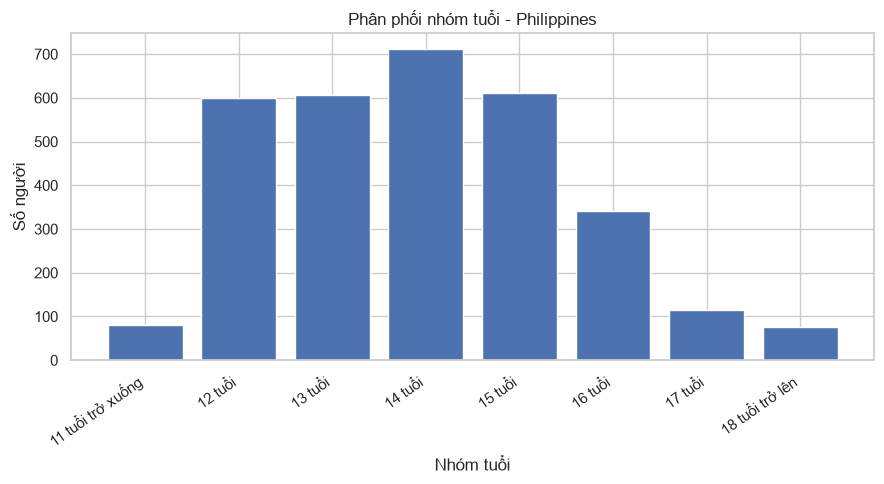

In [18]:
# Biểu đồ độ tuổi
plt.figure(figsize=(9, 5))
age_plot = eda["Q1"].map(age_labels).value_counts()
age_plot = age_plot.reindex(age_labels.values()).dropna()

plt.bar(age_plot.index, age_plot.values)
plt.title("Phân phối nhóm tuổi - Philippines")
plt.xlabel("Nhóm tuổi")
plt.ylabel("Số người")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

Nhận xét: 
    - Nhóm 14 tuổi chiếm nhiều nhất (22,6%). 
    - Nhóm 18 tuổi trở lên chiếm ít nhất (2,39%).

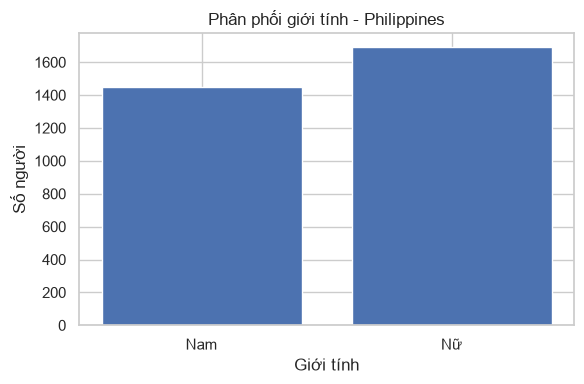

In [19]:
gender_plot = (
    eda["Q2"]
    .map(gender_labels)
    .value_counts()
    .reindex(["Nam", "Nữ"])
)

plt.figure(figsize=(6, 4))
plt.bar(gender_plot.index, gender_plot.values)
plt.title("Phân phối giới tính - Philippines")
plt.xlabel("Giới tính")
plt.ylabel("Số người")
plt.tight_layout()
plt.show()

Nhận xét:
    - Tỷ lệ nữ (53,85%) nhiều hơn tỷ lệ nam (46,15%)

In [20]:
#Phân tích cô đơn, lo lắng và số bạn thân

def make_distribution_table(series):
    counts = series.value_counts().sort_index()
    table = pd.DataFrame({
        "Số lượng": counts,
        "Tỷ lệ (%)": (
            counts / counts.sum() * 100
        ).round(2)
    })
    return table

for question in ["Q22", "Q23", "Q27"]:
    print(f"\nPhân phối {question}:")
    display(make_distribution_table(eda[question]))


Phân phối Q22:


,Số lượng,Tỷ lệ (%)
Q22,,
1.0,332,10.61
2.0,677,21.64
3.0,1400,44.74
4.0,466,14.89
5.0,254,8.12



Phân phối Q23:


,Số lượng,Tỷ lệ (%)
Q23,,
1.0,776,24.82
2.0,832,26.61
3.0,1015,32.46
4.0,369,11.80
5.0,135,4.32



Phân phối Q27:


,Số lượng,Tỷ lệ (%)
Q27,,
1.0,213,6.86
2.0,269,8.66
3.0,313,10.08
4.0,2311,74.40


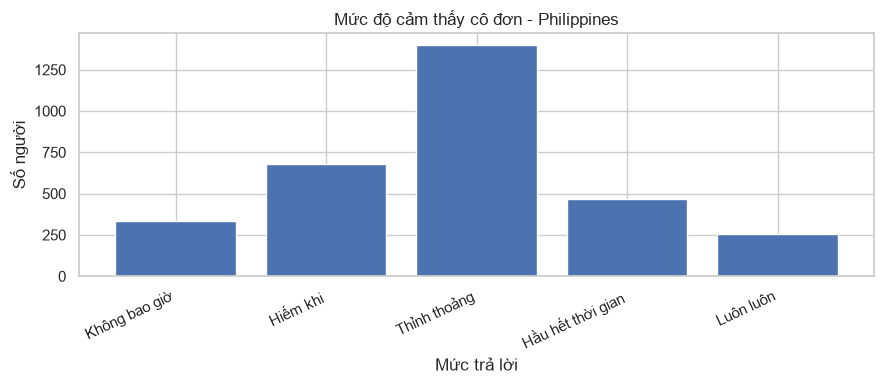

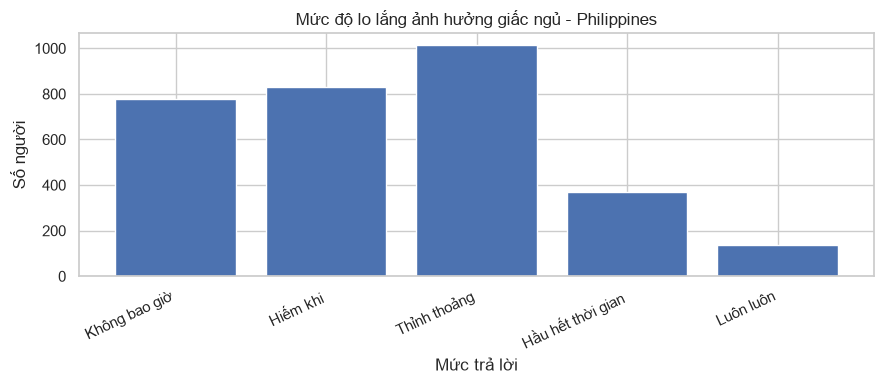

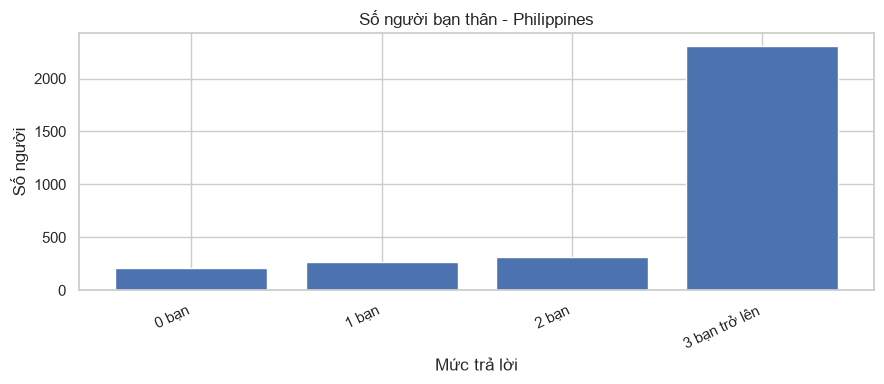

In [21]:
mental_labels = {
    "Q22": {
        1: "Không bao giờ",
        2: "Hiếm khi",
        3: "Thỉnh thoảng",
        4: "Hầu hết thời gian",
        5: "Luôn luôn"
    },
    "Q23": {
        1: "Không bao giờ",
        2: "Hiếm khi",
        3: "Thỉnh thoảng",
        4: "Hầu hết thời gian",
        5: "Luôn luôn"
    },
    "Q27": {
        1: "0 bạn",
        2: "1 bạn",
        3: "2 bạn",
        4: "3 bạn trở lên"
    }
}

plot_titles = {
    "Q22": "Mức độ cảm thấy cô đơn - Philippines",
    "Q23": "Mức độ lo lắng ảnh hưởng giấc ngủ - Philippines",
    "Q27": "Số người bạn thân - Philippines"
}
for question in ["Q22", "Q23", "Q27"]:
    labels = mental_labels[question]
    counts = eda[question].value_counts().sort_index()
    x_labels = [
        labels.get(code, f"Mã {code}")
        for code in counts.index
    ]
    plt.figure(figsize=(9,4))
    plt.bar(x_labels, counts.values)
    plt.title(plot_titles[question])
    plt.xlabel("Mức trả lời")
    plt.ylabel("Số người")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

Nhận xét:
   - Mức độ cảm thấy cô đơn ở mức thỉnh thoảng (44,74%)
   - Mức độ lo lắng ảnh hưởng giấc ngủ cũng ở mức thỉnh thoảng là nhiều chiếm 32,46%
   - Số người bạn thân: có 3 bạn trở lên chiếm tới 74,4%

In [22]:
 #Phân tích biến mục tiêu Q24
Q24_LABELS = {
    1: "Có",
    2: "Không"
}

# Chỉ thống kê các câu trả lời Q24 hợp lệ
q24_valid = eda["Q24"].isin([1,2])
q24 = eda.loc[q24_valid, "Q24"]

print("Tổng số dòng trong CSV:", len(eda))
print("Số câu trả lời Q24 hợp lệ:", int(q24_valid.sum()))
print("Số câu trả lời Q24 thiếu hoặc không hợp lệ:", int((~q24_valid).sum()))

q24_counts = q24.map(Q24_LABELS).value_counts()
q24_counts = q24_counts.reindex(["Có", "Không"], fill_value=0)

q24_table = pd.DataFrame({
    "Số lượng": q24_counts,
    "Tỷ lệ": (
        q24_counts / q24_counts.sum() * 100
    ).round(2)
})

print("\n Phân phối biến mục tiêu Q24:")
display(q24_table)

Tổng số dòng trong CSV: 3149
Số câu trả lời Q24 hợp lệ: 3010
Số câu trả lời Q24 thiếu hoặc không hợp lệ: 139

 Phân phối biến mục tiêu Q24:


,Số lượng,Tỷ lệ
Q24,,
Có,593,19.7
Không,2417,80.3


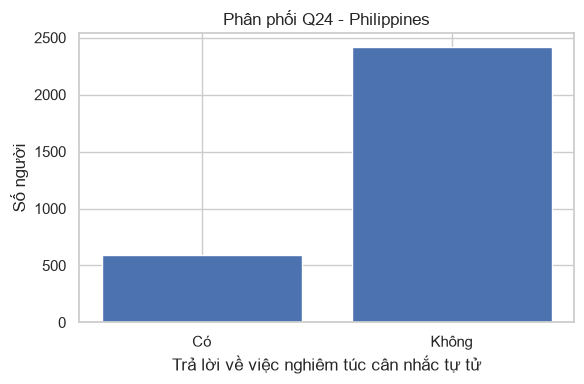

In [23]:
# Vẽ biểu đồ q24

plt.figure(figsize=(6,4))
plt.bar(
    q24_counts.index,
    q24_counts.values
)

plt.title("Phân phối Q24 - Philippines")
plt.xlabel("Trả lời về việc nghiêm túc cân nhắc tự tử")
plt.ylabel("Số người")
plt.tight_layout()
plt.show()

In [31]:
# Kiểm tra mối liên hệ ban đầu với q24

eda_q24 = eda.loc[
    eda["Q24"].isin([1, 2])
].copy()

eda_q24["Q24_label"] = eda_q24["Q24"].map({
    1: "Có",
    2: "Không"
})

eda_q24["Q1_label"] = eda_q24["Q1"].map(age_labels)
eda_q24["Q2_label"] = eda_q24["Q2"].map(gender_labels)

# Thống kê Q24 theo nhóm tuổi
age_suicide_rate = (
    eda_q24.groupby("Q1")
    .agg(
        **{
            "Số trả lời Có": ("Q24", lambda s: (s == 1).sum()),
            "Tổng trả lời hợp lệ Q24": ("Q24", "count"),
        }
    )
    .reset_index()
)

# Tổng số người trong từng nhóm tuổi (Q1 hợp lệ)
age_suicide_rate["Tổng số người trong nhóm tuổi"] = (
    eda.groupby("Q1")["Q1"].count()
    .reindex(age_suicide_rate["Q1"])
    .to_numpy()
)

# Nhãn nhóm tuổi
age_suicide_rate["Nhóm tuổi"] = (
    age_suicide_rate["Q1"].map(age_labels)
)

# Tỷ lệ trả lời Có trên số câu trả lời Q24 hợp lệ
age_suicide_rate["Tỷ lệ Q24 = Có (%)"] = (
    age_suicide_rate["Số trả lời Có"]
    / age_suicide_rate["Tổng trả lời hợp lệ Q24"] * 100
)

# Hiển thị bảng
display(
    age_suicide_rate[
        [
            "Nhóm tuổi",
            "Tổng số người trong nhóm tuổi",
            "Số trả lời Có",
            "Tổng trả lời hợp lệ Q24",
            "Tỷ lệ Q24 = Có (%)"
        ]
    ].round(2)
)
# Thống kê Q24 theo giới tính
gender_suicide_rate = (
    eda_q24.groupby("Q2")
        .agg(
            **{
                "Số trả lời Có": ("Q24", lambda s: (s == 1).sum()),
                "Tổng trả lời hợp lệ Q24": ("Q24", "count"),
            }
        )
        .reset_index()
)
# Tổng số người thuộc giới tính nam / nữ (Q1 hợp lệ)
gender_suicide_rate["Tổng số người theo giới tính"] = (
    eda.groupby("Q2")["Q2"].count()
    .reindex(gender_suicide_rate["Q2"])
    .to_numpy()
)
# Đổi mã giới tính thành nhãn
gender_suicide_rate["Giới tính"] = (
    gender_suicide_rate["Q2"].map(gender_labels)
)
# Tỷ lệ trả lời Có trên số câu trả lời Q24 hợp lệ
gender_suicide_rate["Tỷ lệ Q24 = Có (%)"] = (
    gender_suicide_rate["Số trả lời Có"]
    / gender_suicide_rate["Tổng trả lời hợp lệ Q24"] * 100
)

# Hiển thị bảng
display(
   gender_suicide_rate[
           [
               "Giới tính",
               "Tổng số người theo giới tính",
               "Số trả lời Có",
               "Tổng trả lời hợp lệ Q24",
               "Tỷ lệ Q24 = Có (%)"
           ]
       ].round(2)
)

,Nhóm tuổi,Tổng số người trong nhóm tuổi,Số trả lời Có,Tổng trả lời hợp lệ Q24,Tỷ lệ Q24 = Có (%)
0,11 tuổi trở xuống,81,18,77,23.38
1,12 tuổi,600,80,559,14.31
2,13 tuổi,607,115,573,20.07
3,14 tuổi,712,159,685,23.21
4,15 tuổi,611,124,598,20.74
5,16 tuổi,342,65,330,19.70
6,17 tuổi,114,22,109,20.18
7,18 tuổi trở lên,75,9,72,12.50


,Giới tính,Tổng số người theo giới tính,Số trả lời Có,Tổng trả lời hợp lệ Q24,Tỷ lệ Q24 = Có (%)
0,Nam,1449,238,1349,17.64
1,Nữ,1691,354,1654,21.40


Qua phân tích dữ liệu khảo sát Philippines, tỷ lệ trả lời Có đối với câu hỏi Q24 có sự khác biệt giữa các nhóm tuổi và giới tính. Nhóm 11 tuổi trở xuống có tỷ lệ cao nhất trong các nhóm tuổi được khảo sát (23,38%), trong khi nhóm từ 18 tuổi trở lên có tỷ lệ thấp nhất (12,50%). Theo giới tính, tỷ lệ ở nữ là 21,40%, cao hơn nam (17,64%).

# PHẦN 6. TIỀN XỬ LÝ DỮ LIỆU CHO MACHINE LEARNING

Mục tiêu:
- Chọn các biến đầu vào và biến mục tiêu.
- Kiểm tra giá trị thiếu và mã dữ liệu.
- Xử lý dữ liệu trước khi huấn luyện mô hình.
- Tránh sử dụng các biến gây rò rỉ thông tin mục tiêu.

In [32]:
# Chọn biến đầu vào và biến mục tiêu

FEATURES = ["Q1", "Q2", "Q15", "Q16", "Q17", "Q22", "Q23", "Q27"]
TARGET = "Q24"

#Tạo bản dữ liệu riêng cho Machine Learning
ml_data = eda[FEATURES + [TARGET]].copy()
print("Kích thước dữ liệu ban đầu:", ml_data.shape)
print("\n Số giá trị thiếu theo từng biến:")
display(ml_data.isna().sum().to_frame("Số giá trị thiếu"))
print("\n Phân phối biến mục tiêu Q24:")
display(ml_data[TARGET].value_counts(dropna=False).sort_index())

Kích thước dữ liệu ban đầu: (3149, 9)

 Số giá trị thiếu theo từng biến:


,Số giá trị thiếu
Q1,7
Q2,9
Q15,0
Q16,14
Q17,458
Q22,20
Q23,22
Q27,43
Q24,139



 Phân phối biến mục tiêu Q24:


Q24
1.0     593
2.0    2417
NaN     139
Name: count, dtype: int64

In [34]:
ml_clean = ml_data.copy()

#1. Chỉ giữ các dòng có Q24 hợp lệ: 1 = Có, 2 = Không
ml_clean = ml_clean.loc[
    ml_clean["Q24"].isin([1, 2])
].copy()

print("Kích thước sau khi loại Q24 thiếu", ml_clean.shape)

#2. Kiểm tra giá trị thiếu trong các biến đầu vào
print("\n Giá trị thiếu của các biến đầu vào:")
display(
    ml_clean[FEATURES]
    .isna()
    .sum()
    .to_frame("Số giá trị thiếu")
)
#3. Kiểm tra phân phối mục tiêu sau khi lọc
print("\n Phân phối Q24 sau khi lọc:")
display(ml_clean["Q24"].value_counts().sort_index())

Kích thước sau khi loại Q24 thiếu (3010, 9)

 Giá trị thiếu của các biến đầu vào:


,Số giá trị thiếu
Q1,7
Q2,7
Q15,0
Q16,8
Q17,432
Q22,8
Q23,7
Q27,31



 Phân phối Q24 sau khi lọc:


Q24
1.0     593
2.0    2417
Name: count, dtype: int64

In [35]:
# Điền giá trị thiếu ở các biến đầu vào
ml_imputed = ml_clean.copy()

for col in FEATURES:
    if ml_imputed[col].isna().any():
        mode_value = ml_imputed[col].mode(dropna=True)[0]
        ml_imputed[col] = ml_imputed[col].fillna(mode_value)

print("Kích thước sau khi xử lý:", ml_imputed.shape)
print("\n Số giá trị thiếu còn lại:")
display(
    ml_imputed[FEATURES + [TARGET]]
    .isna()
    .sum()
    .to_frame("Số giá trị thiếu")
)
print("\n Phân phối Q24:")
display(ml_imputed[TARGET].value_counts().sort_index())

Kích thước sau khi xử lý: (3010, 9)

 Số giá trị thiếu còn lại:


,Số giá trị thiếu
Q1,0
Q2,0
Q15,0
Q16,0
Q17,0
Q22,0
Q23,0
Q27,0
Q24,0



 Phân phối Q24:


Q24
1.0     593
2.0    2417
Name: count, dtype: int64

In [36]:
# Tạo nhãn mục tiêu nhị phân
ml_model = ml_imputed.copy()
# Q24: 1 = Có -> 1; 2 = Không -> 0
ml_model["Q24"] = ml_model["Q24"].map({
    1: 1,
    2: 0
}).astype(int)

print("Phân phối nhãn Q24:")
display(
    ml_model["Q24"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Không (0)", 1:"Có (1)"})
    .to_frame("Số người")
)
print("\n Tỷ lệ từng nhãn (%):")
display(
    (
        ml_model["Q24"]
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .rename(index={0: "Không (0)", 1: "Có (1)"})
        .round(2)
        .to_frame("Tỷ lệ (%)")
    )
)

Phân phối nhãn Q24:


,Số người
Q24,
Không (0),2417
Có (1),593



 Tỷ lệ từng nhãn (%):


,Tỷ lệ (%)
Q24,
Không (0),80.3
Có (1),19.7


Chia dữ liệu thành tập huấn luyện và kiểm tra

In [37]:
from sklearn.model_selection import train_test_split
# x: các biến đầu vào,  y: biến mục tiêu
x = ml_model[FEATURES].copy()
y = ml_model["Q24"].copy()

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Kích thước x_train:", x_train.shape)
print("Kích thước x_test:", x_test.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước y_test:", y_test.shape)

print("\n Tỷ lệ nhãn trong tập train (%):")
display((y_train.value_counts(normalize=True) * 100).round(2))
print("\n Tỷ lệ nhãn trong tập test (%):")
display((y_test.value_counts(normalize=True) * 100).round(2))

Kích thước x_train: (2408, 8)
Kích thước x_test: (602, 8)
Kích thước y_train: (2408,)
Kích thước y_test: (602,)

 Tỷ lệ nhãn trong tập train (%):


Q24
0    80.32
1    19.68
Name: proportion, dtype: float64


 Tỷ lệ nhãn trong tập test (%):


Q24
0    80.23
1    19.77
Name: proportion, dtype: float64

In [39]:
from sklearn.model_selection import train_test_split
# Tạo x và y từ dữ liệu chưa điền thiếu
x = ml_clean[FEATURES].copy()
# Q24: 1=Có, 2=Không
y = ml_clean["Q24"].map({1: 1, 2: 0}).astype(int)

# Chia train/test trước khi học giá trị điền thiếu
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("Giá trị thiếu trong x_train:", x_train.isna().sum().sum())
print("Giá trị thiếu trong x_test:", x_test.isna().sum().sum())

x_train: (2408, 8)
x_test: (602, 8)
Giá trị thiếu trong x_train: 398
Giá trị thiếu trong x_test: 102


## Chỉ số đánh giá mô hình 


- TN (True Negative) - Dự đoán âm tính đúng (dự đoán Không và thực tế cũng là Không)
- FP (False Positive)- Dự đoán dương tính sai (dự đoán Có và thực tế là Không)
- FN (False Negative)- Dự đoán âm tính sai (dự đoán Không và thực tế là Có)
- TP (True Positive) - Dự đoán dương tính đúng (dự đoán Có và thực tế cũng là Có)

- Accuracy - Độ chính xác tổng thể = $\frac{TP + TN}{TP + TN + FP + FN}$
- Precision - Độ chính xác của dự đoán Có = $\frac{TP}{TP + FP}$
- Recall - Khả năng nhận diện nhóm Có = $\frac{TP}{TP + FN}$
- F1-score - Chỉ số đánh giá mô hình Machine Learning = 2 x $\frac{Precision * Recall}{Precision + Recall}$
- ROC-AUC - Chỉ số đo lường khả năng phân biệt hai lớp của mô hình phân loại :


    - ROC-AUC là diện tích đường cong ROC(Receiver Operating Characteristic)

    - Đường ROC biểu diễn mối quan hệ giữa: 

        + TPR (True Positive Rate)- chính là Recall = $\frac{TP}{TP + FN}$


        + FPR(False Positive Rate)- tỷ lệ dự đoán nhầm nhóm Không thành Có = $\frac{FP}{FP + TN}$

    - ROC-AUC được tính bằng tích phân: $$AUC_{ROC} = \int_0^1 TPR(FPR) \, d(FPR)$$
- RP-AUC - Chỉ số đánh giá hiệu quả của mô hình phân loại:


    - PR-AUC(Precision-Recall Area Under the Curve) là diện tích dưới đường cong Precision-Recall
    $$AUC_{PR} = \int_0^1 Precision(Recall) \, d(Recall)$$



# Xây dựng mô hình Logistic Regression đầu tiên

In [40]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

SimpleImputer(strategy="most_frequent"): điền giá trị thiếu bằng mã trả lời xuất hiện nhiều nhất, được tính từ tập train.



StandardScaler(): chuẩn hóa thang đo các biến đầu vào.



LogisticRegression(): học cách phân loại Q24 thành 0 = Không hoặc 1 = Có.



fit(x_train, y_train): chỉ huấn luyện trên tập train; tập test được giữ riêng để đánh giá.

In [41]:
# Pipeline: điền giá trị thiếu -> chuẩn hóa -> huấn luyện
logistic_model = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])
# Huấn luyện chỉ trên tập train
logistic_model.fit(x_train, y_train)
print("Đã huấn luyện Logistic Regression thành công!")

Đã huấn luyện Logistic Regression thành công!


In [42]:
# Dự đoán trên tập test
y_pred = logistic_model.predict(x_test)
print("Số dự đoán:", len(y_pred))
print("10 nhãn thực tế đầu tiên:", y_test.iloc[:10].tolist())
print("10 nhãn dự đoán đầu tiên:", y_pred[:10].tolist())

Số dự đoán: 602
10 nhãn thực tế đầu tiên: [1, 0, 0, 0, 0, 0, 1, 0, 0, 0]
10 nhãn dự đoán đầu tiên: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


# Đánh giá mô hình Logistic Regression

In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_auc_score

)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


#Bảng báo cáo phân loại
report = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

df_report = pd.DataFrame(report).transpose()

display(df_report.style
        .format("{:.4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - LOGISTIC REGRESSION")
        .set_properties(**{"text-align": "center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))

,precision,recall,f1-score,support
Không (0),0.8168,0.9876,0.8941,483.000000
Có (1),0.6667,0.1008,0.1752,119.000000
accuracy,0.8123,0.8123,0.8123,0.812292
macro avg,0.7417,0.5442,0.5346,602.000000
weighted avg,0.7871,0.8123,0.7520,602.000000


Nhận xét: 
- Mô hình Logistic Regression đạt Accuracy 81,23%, cho thấy khả năng dự đoán tổng thể khá tốt. 
- Mô hình nhận diện tốt lớp Không (0) với Recall 98,76%, nhưng Recall của lớp Có (1) chỉ đạt 10,08%, tức bỏ sót phần lớn trường hợp thuộc nhóm này.
- F1-score của lớp Có chỉ đạt 17,52%, cho thấy hiệu quả nhận diện chưa cao. 
--> Vì vậy, cần cải thiện khả năng phát hiện lớp Có và so sánh với các mô hình khác để lựa chọn mô hình phù hợp hơn.

In [86]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
y_prob = logistic_model.predict_proba(x_test)[:, 1]
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC (Average Precision)": average_precision_score(y_test, y_prob)
}
print("LOGISTIC REGRESSION")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))

LOGISTIC REGRESSION


,Chỉ số,Giá trị
0,Accuracy,0.8123
1,Precision,0.6667
2,Recall,0.1008
3,F1-score,0.1752
4,ROC-AUC,0.7346
5,PR-AUC (Average Precision),0.4387


Nhận xét:

- Accuracy = 0,8123: mô hình dự đoán đúng khoảng 81% tổng số mẫu.



- Precision = 0,6667: trong số những mẫu được dự đoán Có, khoảng 67% thực tế thuộc nhóm Có.



- Recall = 0,1008: mô hình nhận diện được khoảng 10% số mẫu thực tế thuộc nhóm Có.



- F1-score = 0,1752: thấp do Recall thấp. Cho thấy mô hình bỏ sót nhiều trường hợp thuộc lớp Có



- ROC-AUC = 0,7346: khả năng phân biệt hai nhóm tương đối tốt.



- PR-AUC = 0,4387: khả năng xếp hạng nhóm Có có tín hiệu hơn mức cơ sở khoảng 19,8%.



-> Mô hình cần cải thiện và so sánh với các thuộc tính khác

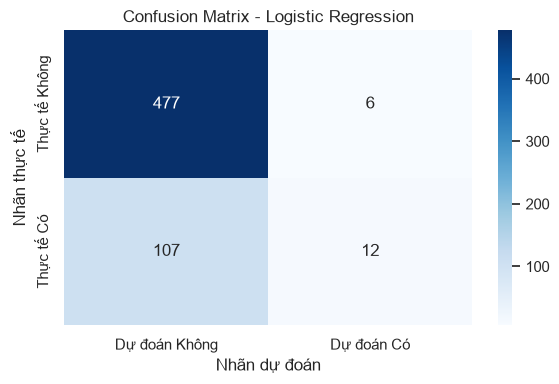

              precision    recall  f1-score   support

   Không (0)       0.82      0.99      0.89       483
      Có (1)       0.67      0.10      0.18       119

    accuracy                           0.81       602
   macro avg       0.74      0.54      0.53       602
weighted avg       0.79      0.81      0.75       602



In [49]:
# Vẽ ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Dự đoán Không", "Dự đoán Có"],
    yticklabels=["Thực tế Không", "Thực tế Có"],
)

plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thực tế")
plt.title("Confusion Matrix - Logistic Regression")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0
))

477 người: dự đoán Không và thực tế trả lời Không.



6 người: dự đoán Có nhưng thực tế trả lời Không.



107 người: thực tế trả lời Có nhưng mô hình dự đoán Không.



12 người: dự đoán đúng nhóm Có.

## Điều chỉnh ngưỡng dự đoán

In [ ]:
#Điều chỉnh ngưỡng dự đoán
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd
# Xác suất dự đoán Q24 = Có
y_proba = logistic_model.predict_proba(x_test)[:, 1]
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]
threshold_results = []

for threshold in thresholds:
    pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test, pred, labels=[0, 1]
    ).ravel()
    threshold_results.append({
        "Ngưỡng": threshold,
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, pred, zero_division=0
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })
threshold_df = pd.DataFrame(threshold_results)
display(
    threshold_df.round(3)
)

,Ngưỡng,Precision,Recall,F1-score,TN,FP,FN,TP
0,0.5,0.667,0.101,0.175,477,6,107,12
1,0.4,0.615,0.202,0.304,468,15,95,24
2,0.3,0.471,0.336,0.392,438,45,79,40
3,0.2,0.338,0.622,0.438,338,145,45,74
4,0.1,0.236,0.950,0.379,118,365,6,113


Ngưỡng 0,2: cân bằng Precision và Recall tốt nhất theo F1-score trong các ngưỡng đã thử. Mô hình nhận diện đúng 74/119 trường hợp Có và bỏ sót 45 trường hợp.



Ngưỡng 0,1: nhận diện được 113/119 trường hợp Có, nhưng có tới 365 trường hợp Không bị dự đoán nhầm thành Có.



Ngưỡng 0,5: Precision khá cao nhưng bỏ sót 107/119 trường hợp Có.

## Huấn luyện mô hình Decision Tree

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

#Xây dựng mô hình Decision Tree
tree_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42
    ))
])
#Huấn luyện
tree_model.fit(x_train, y_train)
# Dự đoán
tree_pred = tree_model.predict(x_test)
tree_proba = tree_model.predict_proba(x_test)[:, 1]
print("Đã huấn luyện Decision Tree thành công!")

Đã huấn luyện Decision Tree thành công!


In [77]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report
)

report = classification_report(
    y_test,
    tree_pred,
    labels=[0,1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

tree_report = pd.DataFrame(report).transpose()
display(tree_report.style
        .format("{:4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - DECISION TREE")
        .set_properties(**{"text-align":"center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))

,precision,recall,f1-score,support
Không (0),0.853774,0.749482,0.798236,483.000000
Có (1),0.320225,0.478992,0.383838,119.000000
accuracy,0.696013,0.696013,0.696013,0.696013
macro avg,0.586999,0.614237,0.591037,602.000000
weighted avg,0.748305,0.696013,0.716320,602.000000


Nhận xét: 


- Mô hình Decision Tree đạt Accuracy 69,60%.
- Với lớp Có (1), Recall đạt 47,90%, cao hơn Logistic Regression, cho thấy mô hình phát hiện được nhiều trường hợp Có hơn.
- Tuy nhiên, Precision chỉ đạt 32,02%, nghĩa là còn nhiều trường hợp dự đoán nhầm. 


--> Decision Tree cải thiện khả năng nhận diện lớp Có nhưng độ chính xác tổng thể thấp hơn Logistic Regression.

In [85]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
tree_proba = tree_model.predict_proba(x_test)[:, 1]
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, tree_pred),
    "Precision": precision_score(y_test, tree_pred, zero_division=0),
    "Recall": recall_score(y_test, tree_pred, zero_division=0),
    "F1-score": f1_score(y_test, tree_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tree_proba),
    "PR-AUC (Average Precision)": average_precision_score(y_test, tree_proba)
}
print("DECISION TREE")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))


DECISION TREE


,Chỉ số,Giá trị
0,Accuracy,0.6960
1,Precision,0.3202
2,Recall,0.4790
3,F1-score,0.3838
4,ROC-AUC,0.6640
5,PR-AUC (Average Precision),0.3208


- Accuracy = 0,6960: Mô hình dự đoán đúng khoảng 69,60% tổng số mẫu.



- Precision = 0,3202: Trong số những mẫu được dự đoán Có, khoảng 32,02% thực tế thuộc nhóm Có.



- Recall = 0,4790: Mô hình nhận diện được khoảng 47,90% số mẫu thực tế thuộc nhóm Có.



- F1-score = 0,3838: Cho thấy mức cân bằng giữa Precision và Recall của nhóm Có còn hạn chế.



- ROC-AUC = 0,6640: Khả năng phân biệt hai nhóm tốt hơn mức ngẫu nhiên, nhưng hiệu quả vẫn chưa cao.



- PR-AUC = 0,3208: Chất lượng xếp hạng nhóm Có còn khiêm tốn, tuy nhiên cao hơn tỷ lệ nhóm Có trong tập kiểm tra (khoảng 19,8%).

## Huấn luyện mô hình Random Forest


In [55]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

#Xây dựng mô hình Random Forest
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

#Huấn luyện trên tập train
rf_model.fit(x_train, y_train)
#Dự đoán trên tập test
rf_pred = rf_model.predict(x_test)
rf_proba = rf_model.predict_proba(x_test)[:, 1]
print("Đã huấn luyện Random Forest thành công!")

Đã huấn luyện Random Forest thành công!


In [79]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    classification_report
)


report = classification_report(
    y_test,
    rf_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

rf_report = pd.DataFrame(report).transpose()

display(rf_report.style
        .format("{:.4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - RANDOM FOREST")
        .set_properties(**{"text-align": "center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))


,precision,recall,f1-score,support
Không (0),0.8772,0.7101,0.7849,483.000000
Có (1),0.3365,0.5966,0.4303,119.000000
accuracy,0.6877,0.6877,0.6877,0.687708
macro avg,0.6069,0.6534,0.6076,602.000000
weighted avg,0.7703,0.6877,0.7148,602.000000


Nhận xét: 


- Mô hình Random Forest đạt Accuracy 68,77%. 
- Với lớp Có (1), Recall đạt 59,66% và F1-score đạt 43,03%, cho thấy mô hình phát hiện các trường hợp Có tốt hơn Logistic Regression và Decision Tree. 
- Tuy nhiên, Precision chỉ đạt 33,65%, nghĩa là vẫn còn nhiều trường hợp dự đoán nhầm. 



-->Nhìn chung, Random Forest có khả năng nhận diện lớp Có tốt nhất trong ba mô hình đã đánh giá, nhưng độ chính xác tổng thể còn hạn chế.

In [87]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
rf_proba = rf_model.predict_proba(x_test)[:, 1]
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_pred, zero_division=0),
    "F1-score": f1_score(y_test, rf_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, rf_proba),
    "PR-AUC (Average Precision)": average_precision_score(y_test, rf_proba)
}
print("RANDOM FOREST")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))


RANDOM FOREST


,Chỉ số,Giá trị
0,Accuracy,0.6877
1,Precision,0.3365
2,Recall,0.5966
3,F1-score,0.4303
4,ROC-AUC,0.7100
5,PR-AUC (Average Precision),0.4033


- Accuracy = 0,6877: Mô hình dự đoán đúng khoảng 68,77% tổng số mẫu.



- Precision = 0,3365: Trong số những mẫu được dự đoán Có, khoảng 33,65% thực tế thuộc nhóm Có.



- Recall = 0,5966: Mô hình nhận diện được khoảng 59,66% số mẫu thực tế thuộc nhóm Có.



- F1-score = 0,4303: Cho thấy sự cân bằng giữa Precision và Recall của nhóm Có tốt hơn Decision Tree.



- ROC-AUC = 0,7100: Khả năng phân biệt hai nhóm ở mức tương đối, tốt hơn Decision Tree.



- PR-AUC = 0,4033: Chất lượng xếp hạng nhóm Có khá hơn Decision Tree và cao hơn tỷ lệ nhóm Có trong tập kiểm tra (khoảng 19,8%).

## Huấn luyện mô hình Gradient Boosting

In [60]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier

gb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb_model.fit(x_train, y_train)

gb_pred = gb_model.predict(x_test)
gb_proba = gb_model.predict_proba(x_test)[:, 1]

print("Đã huấn luyện Gradient Boosting thành công!")

Đã huấn luyện Gradient Boosting thành công!


In [82]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

#Bảng báo cáo phân loại
report = classification_report(
    y_test,
    gb_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

gb_report = pd.DataFrame(report).transpose()

display(gb_report.style
        .format("{:.4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - GRADIENT BOOSTING")
        .set_properties(**{"text-align": "center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))


,precision,recall,f1-score,support
Không (0),0.8240,0.9793,0.8950,483.000000
Có (1),0.6429,0.1513,0.2449,119.000000
accuracy,0.8156,0.8156,0.8156,0.815615
macro avg,0.7334,0.5653,0.5699,602.000000
weighted avg,0.7882,0.8156,0.7665,602.000000


Nhận xét: 


- Mô hình Gradient Boosting đạt Accuracy 81,56%, cao nhất trong các mô hình đã đánh giá. 
- Mô hình nhận diện tốt lớp Không (0) với Recall 97,93%, nhưng Recall của lớp Có (1) chỉ đạt 15,13%, cho thấy vẫn bỏ sót nhiều trường hợp.
- F1-score của lớp Có đạt 24,49%, cao hơn Logistic Regression nhưng thấp hơn Decision Tree và Random Forest. 



--> Nhìn chung, mô hình có độ chính xác tổng thể cao nhưng khả năng phát hiện lớp Có còn hạn chế.

In [88]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
gb_proba = gb_model.predict_proba(x_test)[:, 1]
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, gb_pred),
    "Precision": precision_score(y_test, gb_pred, zero_division=0),
    "Recall": recall_score(y_test, gb_pred, zero_division=0),
    "F1-score": f1_score(y_test, gb_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, gb_proba),
    "PR-AUC (Average Precision)": average_precision_score(y_test, gb_proba)
}
print("GRADIENT BOOSTING")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))



GRADIENT BOOSTING


,Chỉ số,Giá trị
0,Accuracy,0.8156
1,Precision,0.6429
2,Recall,0.1513
3,F1-score,0.2449
4,ROC-AUC,0.7183
5,PR-AUC (Average Precision),0.4109


- Accuracy = 0,8156: Mô hình dự đoán đúng khoảng 81,56% tổng số mẫu.



- Precision = 0,6429: Trong số những mẫu được dự đoán Có, khoảng 64,29% thực tế thuộc nhóm Có.



- Recall = 0,1513: Mô hình chỉ nhận diện được khoảng 15,13% số mẫu thực tế thuộc nhóm Có.



- F1-score = 0,2449: Thấp do Recall thấp, cho thấy khả năng cân bằng giữa Precision và Recall của nhóm Có chưa tốt.



- ROC-AUC = 0,7183: Mô hình có khả năng phân biệt hai nhóm ở mức tương đối.



- PR-AUC = 0,4109: Chất lượng xếp hạng nhóm Có cao hơn tỷ lệ cơ sở khoảng 19,8%, nhưng khả năng nhận diện nhóm Có vẫn còn hạn chế ở ngưỡng dự đoán hiện tại.

## Deep Learning bằng mạng nơ-ron nhân tạo Neural Network(MLP)

In [89]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Điền giá trị thiếu
imputer = SimpleImputer(strategy="most_frequent")

x_train_dl = imputer.fit_transform(x_train)
x_test_dl = imputer.transform(x_test)

# Chuẩn hóa dữ liệu
scaler = StandardScaler()

x_train_dl = scaler.fit_transform(x_train_dl)
x_test_dl = scaler.transform(x_test_dl)

print("x_train:", x_train_dl.shape)
print("x_test:", x_test_dl.shape)
print("Chuẩn bị dữ liệu Deep Learning thành công!")

x_train: (2408, 8)
x_test: (602, 8)
Chuẩn bị dữ liệu Deep Learning thành công!


In [90]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

tf.random.set_seed(42)

nn_model = Sequential([
    Input(shape=(x_train_dl.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

nn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

Huấn luyện mô hình

In [91]:
history = nn_model.fit(
    x_train_dl,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7684 - loss: 0.5493 - val_accuracy: 0.7925 - val_loss: 0.4926
Epoch 2/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8053 - loss: 0.4792 - val_accuracy: 0.7946 - val_loss: 0.4812
Epoch 3/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8043 - loss: 0.4658 - val_accuracy: 0.8029 - val_loss: 0.4786
Epoch 4/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8032 - loss: 0.4681 - val_accuracy: 0.8050 - val_loss: 0.4763
Epoch 5/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8131 - loss: 0.4608 - val_accuracy: 0.8029 - val_loss: 0.4760
Epoch 6/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8089 - loss: 0.4514 - val_accuracy: 0.8029 - val_loss: 0.4770
Epoch 7/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8105 - loss: 0.4539 - val_accuracy: 0.8029 - val_loss: 0.4762
Epoch 8/50
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8110 - loss: 0.4542 - val_accuracy: 0.8008 - val_loss:

In [92]:
import numpy as np

# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
nn_proba = nn_model.predict(x_test_dl).ravel()

# Chuyển xác suất thành nhãn 0 hoặc 1
nn_pred = (nn_proba >= 0.5).astype(int)

print("Đã dự đoán xong!")
print("Số mẫu kiểm tra:", len(nn_pred))

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Đã dự đoán xong!
Số mẫu kiểm tra: 602


In [93]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)


#Bảng báo cáo phân loại
report = classification_report(
    y_test,
    nn_pred,
    labels=[0, 1],
    target_names=["Không (0)", "Có (1)"],
    zero_division=0,
    output_dict=True
)

nn_report = pd.DataFrame(report).transpose()

display(nn_report.style
        .format("{:.4f}", subset=["precision", "recall", "f1-score"])
        .set_caption("BÁO CÁO PHÂN LOẠI - NEURAL NETWORK")
        .set_properties(**{"text-align": "center"})
        .set_table_styles([
            {"selector": "caption",
             "props": [("font-size", "16px"),
                       ("font-weight", "bold"),
                       ("text-align", "center")]},
            {"selector": "th",
             "props": [("text-align", "center"),
                       ("background-color", "#050D13")]}
        ]))


,precision,recall,f1-score,support
Không (0),0.8183,0.9793,0.8916,483.000000
Có (1),0.5833,0.1176,0.1958,119.000000
accuracy,0.8090,0.8090,0.8090,0.808970
macro avg,0.7008,0.5485,0.5437,602.000000
weighted avg,0.7719,0.8090,0.7541,602.000000


Nhận xét: 


- Mô hình Neural Network đạt Accuracy = 80.90%
- Phân loại tốt nhóm Không với Recall = 97.93% và F1-score = 0.8916.
- Tuy nhiên, nhóm Có có Recall chỉ đạt 11.76% và F1-score = 0.1958, cho thấy mô hình bỏ sót nhiều trường hợp thực tế.



--> Nhìn chung, mô hình có độ chính xác tổng thể khá cao nhưng chưa nhận diện tốt nhóm thiểu số, cần cải thiện để cân bằng khả năng phân loại giữa hai nhóm.

In [ ]:
# Xác suất dự đoán thuộc nhóm Có (Q24 = 1)
nn_proba = nn_model.predict(x_test_dl, verbose=0).ravel()
# Chuyển xác suất thành nhãn 0 hoặc 1
nn_pred = (nn_proba >= 0.5).astype(int)
# Tính các chỉ số đánh giá
metrics = {
    "Accuracy": accuracy_score(y_test, nn_pred),
    "Precision": precision_score(y_test, nn_pred, zero_division=0),
    "Recall": recall_score(y_test, nn_pred, zero_division=0),
    "F1-score": f1_score(y_test, nn_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, nn_proba),
    "PR-AUC (Average Precision)": average_precision_score(y_test, nn_proba)
}
print("NEURAL NETWORK")
metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Chỉ số", "Giá trị"]
)
display(metrics_df.round(4))


NEURAL NETWORK


,Chỉ số,Giá trị
0,Accuracy,0.8090
1,Precision,0.5833
2,Recall,0.1176
3,F1-score,0.1958
4,ROC-AUC,0.7029
5,PR-AUC (Average Precision),0.4009


- Accuracy = 0,8090: Mô hình dự đoán đúng khoảng 80,90% tổng số mẫu.

- Precision = 0,5833: Trong số những mẫu được dự đoán Có, khoảng 58,33% thực tế thuộc nhóm Có.

- Recall = 0,1176: Mô hình chỉ nhận diện được khoảng 11,76% số mẫu thực tế thuộc nhóm Có.

- F1-score = 0,1958: Thấp do Recall thấp, cho thấy khả năng cân bằng giữa Precision và Recall của nhóm Có chưa tốt.

- ROC-AUC = 0,7029: Mô hình có khả năng phân biệt hai nhóm ở mức tương đối.

- PR-AUC = 0,4009: Khả năng xếp hạng và nhận diện nhóm Có còn hạn chế, dù mô hình có thể phân biệt hai nhóm ở các ngưỡng dự đoán khác nhau.

## TỔNG HỢP VÀ SO SÁNH 5 MÔ HÌNH MACHINE LEARNING VÀ DEEP LEARNING

In [96]:
# Tổng hợp kết quả 5 mô hình
comparison_data = [
    {
        "Mô hình": "Logistic Regression",
        "Accuracy": 0.8123,
        "Precision": 0.6667,
        "Recall": 0.1008,
        "F1-score": 0.1752,
        "ROC-AUC": 0.7346,
        "PR-AUC": 0.4387
    },
    {
        "Mô hình": "Decision Tree",
        "Accuracy": 0.6960,
        "Precision": 0.3202,
        "Recall": 0.4790,
        "F1-score": 0.3838,
        "ROC-AUC": 0.6640,
        "PR-AUC": 0.3208
    },
    {
        "Mô hình": "Random Forest",
        "Accuracy": 0.6877,
        "Precision": 0.3365,
        "Recall": 0.5966,
        "F1-score": 0.4303,
        "ROC-AUC": 0.7100,
        "PR-AUC": 0.4033
    },
    {
        "Mô hình": "Gradient Boosting",
        "Accuracy": 0.8156,
        "Precision": 0.6429,
        "Recall": 0.1513,
        "F1-score": 0.2449,
        "ROC-AUC": 0.7183,
        "PR-AUC": 0.4109
    },
    {
        "Mô hình": "Neural Network",
        "Accuracy": 0.8090,
        "Precision": 0.5833,
        "Recall": 0.1176,
        "F1-score": 0.1958,
        "ROC-AUC": 0.7029,
        "PR-AUC": 0.4009
    }
]

comparison_df = pd.DataFrame(comparison_data)

display(comparison_df.round(4))

,Mô hình,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8123,0.6667,0.1008,0.1752,0.7346,0.4387
1,Decision Tree,0.6960,0.3202,0.4790,0.3838,0.6640,0.3208
2,Random Forest,0.6877,0.3365,0.5966,0.4303,0.7100,0.4033
3,Gradient Boosting,0.8156,0.6429,0.1513,0.2449,0.7183,0.4109
4,Neural Network,0.8090,0.5833,0.1176,0.1958,0.7029,0.4009


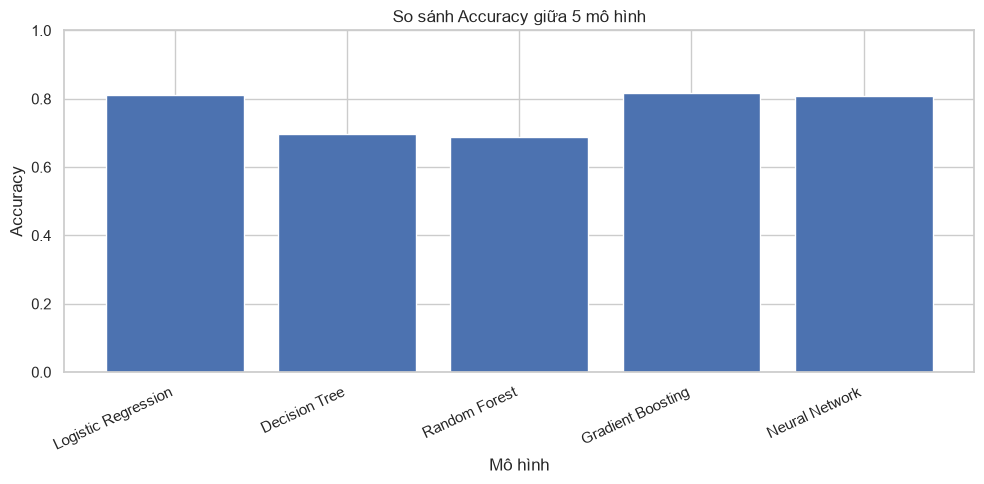

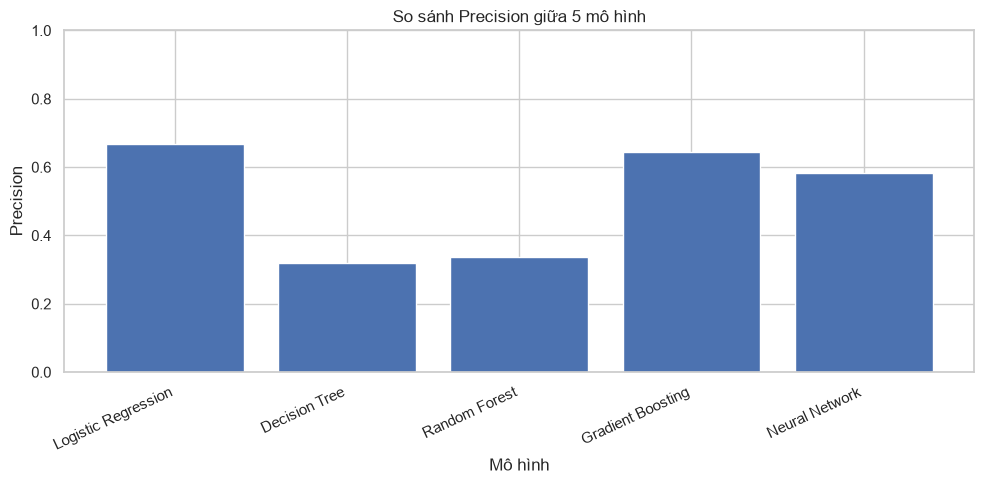

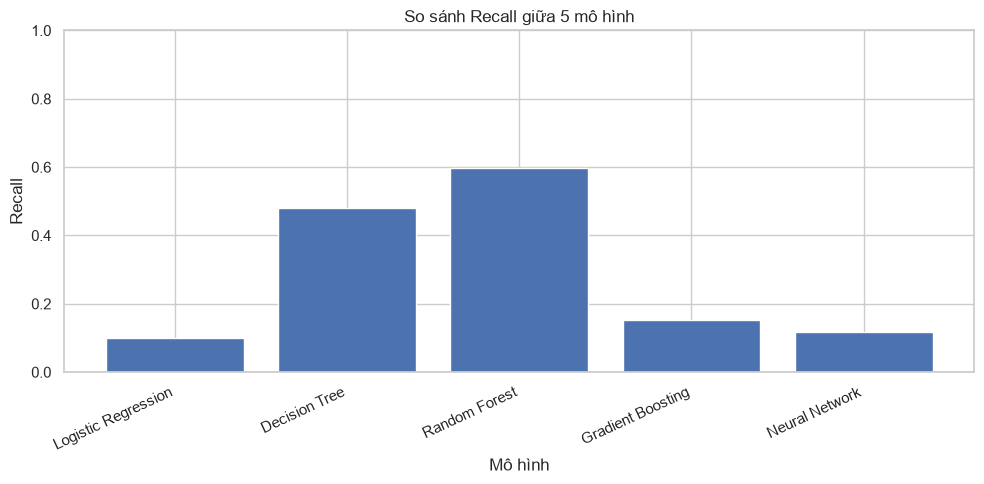

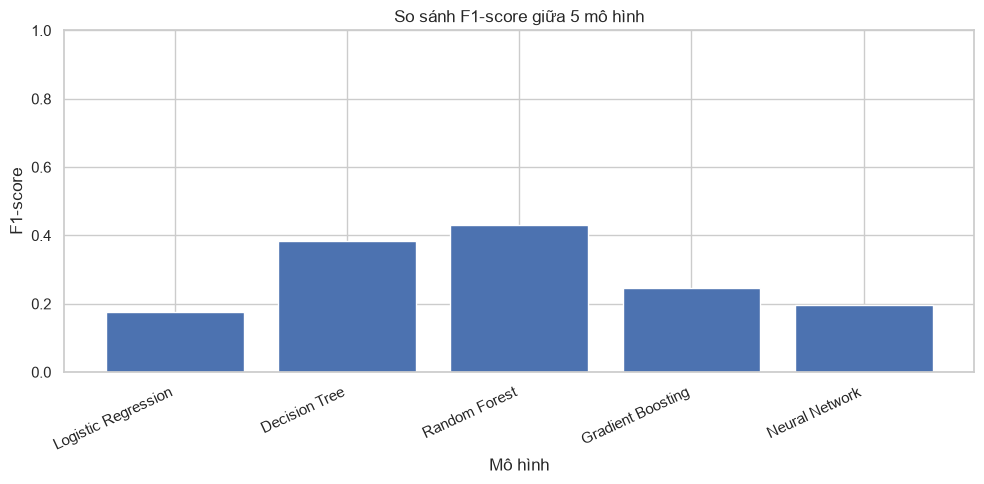

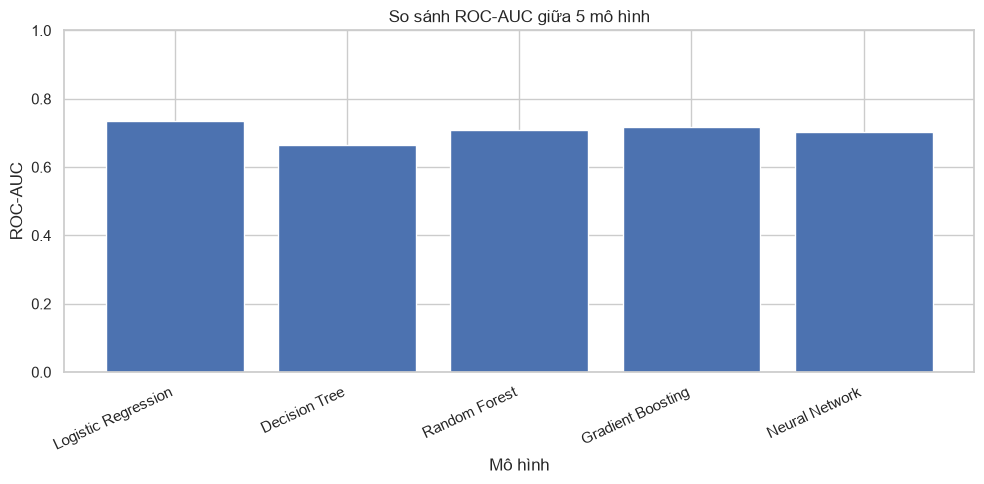

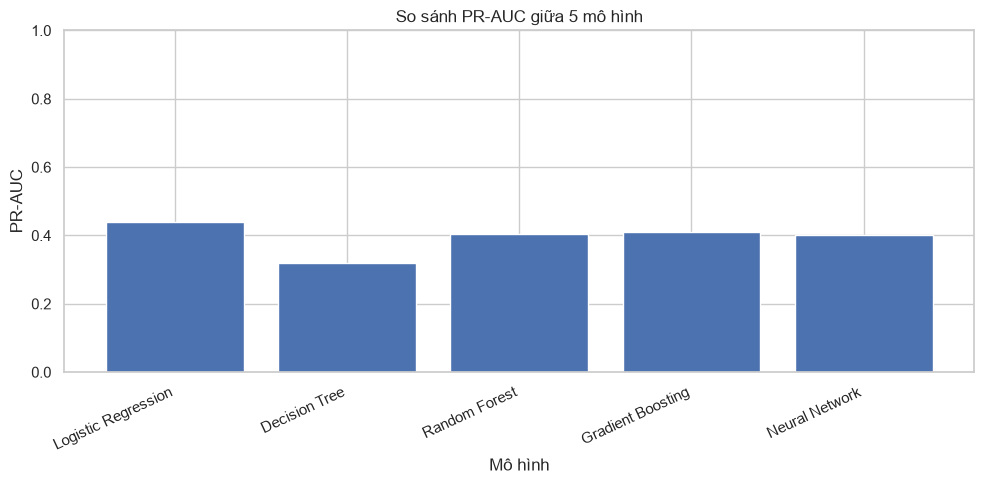

In [97]:
metrics_to_plot = [
    "Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"
]

for metric in metrics_to_plot:
    plt.figure(figsize=(10, 5))
    plt.bar(
        comparison_df["Mô hình"],
        comparison_df[metric]
    )
    plt.title(f"So sánh {metric} giữa 5 mô hình")
    plt.xlabel("Mô hình")
    plt.ylabel(metric)
    plt.ylim(0, 1)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

In [98]:
for metric in metrics_to_plot:
    best_idx = comparison_df[metric].idxmax()

    print(
        f"{metric}: {comparison_df.loc[best_idx, 'Mô hình']}"
        f"({comparison_df.loc[best_idx, metric]:.4f})"
    )

Accuracy: Gradient Boosting(0.8156)
Precision: Logistic Regression(0.6667)
Recall: Random Forest(0.5966)
F1-score: Random Forest(0.4303)
ROC-AUC: Logistic Regression(0.7346)
PR-AUC: Logistic Regression(0.4387)


Nhận xét:
- Gradient Boosting có Accuracy cao nhất 81,56%
- Random Forest có Recall cao nhất 59,66% và F1-score cao nhất 43,03%.
- Logistic Regression có Precision cao nhất 66,67%, có ROC-AUC cao nhất 0,7346 và PR-AUC cao nhất 0,4387.
- Cả 5 mô hình đều có hạn chế trong việc phát hiện nhóm Có, dù Random Forest thể hiện tốt hơn về Recall


--> Nếu mục tiêu là phát hiện nhiều trường hợp thuộc nhóm Có, Random Forest là ứng viên đáng xem xét nhất trong 5 mô hình hiện tại. Tuy nhiên, cần đánh giá thêm và cân nhắc điều chỉnh mô hình trước khi kết luận cuối cùng.

## CẢI THIỆN MÔ HÌNH RANDOM FOREST

In [99]:
import numpy as np
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, average_precision_score, roc_auc_score
)

# Lấy xác suất dự đoán nhóm Có (Q24 = 1)
rf_proba = rf_model.predict_proba(x_test)[:, 1]

print("Đã lấy xác suất dự đoán!")
print("5 xác suất đầu tiên:", rf_proba[:5])

Đã lấy xác suất dự đoán!
5 xác suất đầu tiên: [0.54568154 0.44870209 0.2044519  0.2673144  0.53447248]


In [100]:
#Thử nhiều ngưỡng dự đoán
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

threshold_results = []

for threshold in thresholds:
    rf_pred_threshold = (rf_proba >= threshold).astype(int)

    threshold_results.append({
        "Ngưỡng": threshold,
        "Accuracy": accuracy_score(y_test, rf_pred_threshold),
        "Precision": precision_score(
            y_test, rf_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, rf_pred_threshold, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, rf_pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

,Ngưỡng,Accuracy,Precision,Recall,F1-score
0,0.2,0.2475,0.2060,0.9832,0.3406
1,0.3,0.3754,0.2328,0.9412,0.3733
2,0.4,0.5814,0.2875,0.7563,0.4167
3,0.5,0.6877,0.3365,0.5966,0.4303
4,0.6,0.7608,0.3810,0.3361,0.3571


Vẽ biểu đồ so sánh


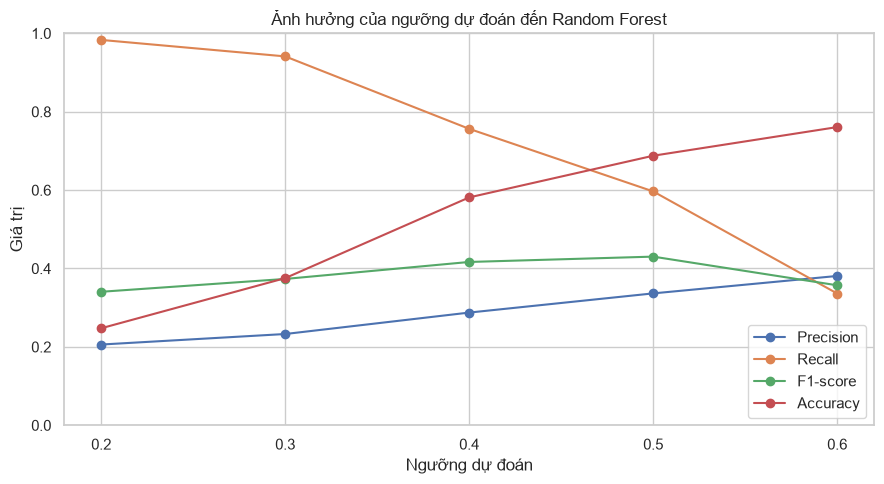

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for metric in ["Precision", "Recall", "F1-score", "Accuracy"]:
    plt.plot(
        threshold_df["Ngưỡng"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.title("Ảnh hưởng của ngưỡng dự đoán đến Random Forest")
plt.xlabel("Ngưỡng dự đoán")
plt.ylabel("Giá trị")
plt.xticks(thresholds)
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Nhận xét kết quả điều chỉnh ngưỡng Random Forest:
- Khi giảm ngưỡng dự đoán, Recall tăng, giúp mô hình phát hiện được nhiều trường hợp Có hơn; tuy nhiên, Precision có xu hướng giảm.
- Khi tăng ngưỡng dự đoán, Precision tăng nhưng Recall giảm, khiến mô hình bỏ sót nhiều trường hợp Có hơn.
- F1-score cao nhất tại ngưỡng 0,5 với giá trị 0,42, tiếp theo là ngưỡng 0,4 với 0,41. Ở ngưỡng 0,6, F1-score giảm còn 0,33.

Kết luận: Với mục tiêu cân bằng Precision và Recall, ngưỡng 0,5 là lựa chọn tốt nhất trong các ngưỡng đã thử. Tuy nhiên, nếu ưu tiên phát hiện nhiều trường hợp Có, cần cân nhắc ngưỡng thấp hơn dựa trên mức Recall và Precision chấp nhận được.

In [104]:
import pandas as pd
import matplotlib.pyplot as plt

# Lấy mô hình Random Forest bên trong Pipeline
rf_estimator = rf_model.named_steps["classifier"]

# Tính mức độ quan trọng của các đặc trưng
feature_importance = pd.DataFrame({
    "Đặc trưng": FEATURES,
    "Mức độ quan trọng": rf_estimator.feature_importances_
})

# Sắp xếp giảm dần
feature_importance = feature_importance.sort_values(
    by="Mức độ quan trọng",
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

,Đặc trưng,Mức độ quan trọng
0,Q22,0.2741
1,Q23,0.2071
2,Q15,0.1119
3,Q17,0.1099
4,Q16,0.0927
5,Q27,0.0872
6,Q1,0.0821
7,Q2,0.0351


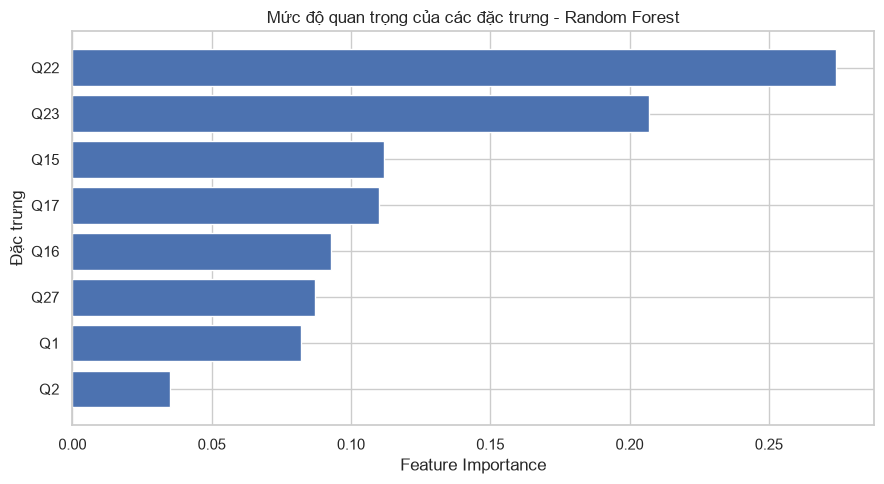

In [105]:
plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Đặc trưng"][::-1],
    feature_importance["Mức độ quan trọng"][::-1]
)

plt.title("Mức độ quan trọng của các đặc trưng - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

Nhận xét Feature Importance
- Q22 = 0,275 và Q23 = 0,210: Là hai đặc trưng quan trọng nhất, đóng góp lớn nhất vào kết quả dự đoán của mô hình Random Forest.
- Q15, Q17, Q16, Q27 và Q1: Có mức độ quan trọng trung bình, dao động khoảng 0,082–0,112.
- Q2 = 0,035: Có mức độ quan trọng thấp nhất trong 8 đặc trưng.

Kết luận: Q22 và Q23 là hai biến đóng góp nhiều nhất vào khả năng dự đoán của mô hình, trong khi Q2 đóng góp ít nhất. Tuy nhiên, Feature Importance chỉ phản ánh mức độ đóng góp vào dự đoán, không chứng minh các biến này có quan hệ nhân quả với kết quả Q24.

## TỔNG KẾT KẾT QUẢ 5 MÔ HÌNH

In [106]:
# Sắp xếp các mô hình theo F1-score giảm dần
comparison_sorted = comparison_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(comparison_sorted.round(4))

best_model = comparison_sorted.iloc[0]

print("Mô hình có F1-score cao nhất:", best_model["Mô hình"])
print("F1-score:", round(best_model["F1-score"], 4))
print("Recall:", round(best_model["Recall"], 4))
print("PR-AUC:", round(best_model["PR-AUC"], 4))

,Mô hình,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Random Forest,0.6877,0.3365,0.5966,0.4303,0.7100,0.4033
1,Decision Tree,0.6960,0.3202,0.4790,0.3838,0.6640,0.3208
2,Gradient Boosting,0.8156,0.6429,0.1513,0.2449,0.7183,0.4109
3,Neural Network,0.8090,0.5833,0.1176,0.1958,0.7029,0.4009
4,Logistic Regression,0.8123,0.6667,0.1008,0.1752,0.7346,0.4387


Mô hình có F1-score cao nhất: Random Forest
F1-score: 0.4303
Recall: 0.5966
PR-AUC: 0.4033


## KẾT LUẬN

Qua quá trình thử nghiệm 5 mô hình, Random Forest đạt kết quả tốt nhất về F1-score (0,4303) và Recall (0,5966), cho thấy khả năng nhận diện nhóm Có tốt hơn các mô hình còn lại. Gradient Boosting đạt Accuracy cao nhất (0,8156), trong khi Logistic Regression có ROC-AUC (0,7346) và PR-AUC (0,4387) cao nhất. Kết quả cho thấy chưa có mô hình nào vượt trội trên tất cả các chỉ số. Random Forest là lựa chọn đáng cân nhắc nếu ưu tiên phát hiện nhóm Có, tuy nhiên vẫn cần cải thiện hiệu quả phân loại và đánh giá thêm trước khi áp dụng thực tế.